# Imoprt and Install Libraries 

In [ ]:
pip install matplotlib

In [ ]:
pip install statsmodels

In [ ]:
pip install scikit-learn

In [165]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)
import matplotlib.pyplot as plt


# Import dataset

In [44]:
df = pd.read_csv(r"C:\Users\bilal\Desktop\gitRepo\Locked\LockedItems\Datasets\Span_new.csv")

# Exploratory data analysis

In [45]:
df.tail()

,Unnamed: 0,ID,make,model,months_old,power,gear,fuel_type,kms,price,age
92380,93986,38173,Opel,Astra,275,52,manual,gasoline,134700,350,1995
92381,93987,57303,Volkswagen,Polo,232,37,manual,gasoline,67762,350,1998
92382,93988,14541,Bmw,320,186,125,manual,gasoline,200000,300,2002
92383,93989,103604,Seat,Toledo,276,66,manual,gasoline,196000,300,1995
92384,93990,99672,Seat,Cordoba,232,81,manual,diesel,150000,200,1998


In [46]:
df.head()

,Unnamed: 0,ID,make,model,months_old,power,gear,fuel_type,kms,price,age
0,0,97860,Porsche,911,240,210,manual,gasoline,202000,999999,1998
1,1,27821,Ford,Mustang,54,487,manual,gasoline,30000,685000,2013
2,2,97801,Porsche,911,358,220,manual,gasoline,56300,555555,1988
3,3,98251,Porsche,911,14,368,manual,gasoline,2800,470000,2016
4,4,98250,Porsche,911,3,515,unknown,gasoline,10,450000,2017


In [47]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 92385 entries, 0 to 92384
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Unnamed: 0  92385 non-null  int64
 1   ID          92385 non-null  int64
 2   make        92385 non-null  str  
 3   model       92385 non-null  str  
 4   months_old  92385 non-null  int64
 5   power       92385 non-null  int64
 6   gear        92385 non-null  str  
 7   fuel_type   92385 non-null  str  
 8   kms         92385 non-null  int64
 9   price       92385 non-null  int64
 10  age         92385 non-null  int64
dtypes: int64(7), str(4)
memory usage: 9.9 MB


In [48]:
df.columns

Index(['Unnamed: 0', 'ID', 'make', 'model', 'months_old', 'power', 'gear',
       'fuel_type', 'kms', 'price', 'age'],
      dtype='str')

In [49]:
df.isnull().sum()

Unnamed: 0    0
ID            0
make          0
model         0
months_old    0
power         0
gear          0
fuel_type     0
kms           0
price         0
age           0
dtype: int64

In [50]:
df.describe(include="all")

,Unnamed: 0,ID,make,model,months_old,power,gear,fuel_type,kms,price,age
count,92385.000000,92385.000000,92385,92385,92385.000000,92385.000000,92385,92385,92385.000000,92385.000000,92385.000000
unique,NaN,NaN,36,247,NaN,NaN,4,6,NaN,NaN,NaN
top,NaN,NaN,Bmw,Golf,NaN,NaN,manual,diesel,NaN,NaN,NaN
freq,NaN,NaN,10546,2433,NaN,NaN,66584,70699,NaN,NaN,NaN
mean,47257.588948,55127.578644,NaN,NaN,63.781436,99.817936,NaN,NaN,83161.963068,16511.689203,2012.238437
std,27180.244200,33146.298945,NaN,NaN,56.871827,42.749383,NaN,NaN,75231.338722,15568.470902,4.751661
min,0.000000,25.000000,NaN,NaN,1.000000,0.000000,NaN,NaN,1.000000,200.000000,1987.000000
25%,23696.000000,25434.000000,NaN,NaN,17.000000,77.000000,NaN,NaN,18616.000000,8500.000000,2009.000000
50%,47461.000000,53909.000000,NaN,NaN,46.000000,88.000000,NaN,NaN,66687.000000,13345.000000,2014.000000
75%,70849.000000,83611.000000,NaN,NaN,97.000000,110.000000,NaN,NaN,129000.000000,19990.000000,2016.000000


In [51]:
df.gear.value_counts()

gear
manual            66584
automatic         24275
unknown            1234
semi-automatic      292
Name: count, dtype: int64

In [32]:
df.columns

Index(['Unnamed: 0', 'ID', 'make', 'model', 'months_old', 'power', 'gear',
       'fuel_type', 'kms', 'price', 'age'],
      dtype='str')

In [53]:
df.drop([3,4,5,6,7], axis = 0, inplace= True)

In [54]:
len(df.columns)

11

In [55]:
df.info

<bound method DataFrame.info of        Unnamed: 0      ID        make        model  months_old  power       gear fuel_type     kms   price   age
0               0   97860     Porsche          911         240    210     manual  gasoline  202000  999999  1998
1               1   27821        Ford      Mustang          54    487     manual  gasoline   30000  685000  2013
2               2   97801     Porsche          911         358    220     manual  gasoline   56300  555555  1988
8               8   62403     Bentley  Continental           5    522  automatic  gasoline    1200  302900  2017
9               9   62402     Bentley  Continental          14    522  automatic  gasoline   17900  289700  2016
...           ...     ...         ...          ...         ...    ...        ...       ...     ...     ...   ...
92380       93986   38173        Opel        Astra         275     52     manual  gasoline  134700     350  1995
92381       93987   57303  Volkswagen         Polo         232  

In [57]:
df.head(10)

,Unnamed: 0,ID,make,model,months_old,power,gear,fuel_type,kms,price,age
0,0,97860,Porsche,911,240,210,manual,gasoline,202000,999999,1998
1,1,27821,Ford,Mustang,54,487,manual,gasoline,30000,685000,2013
2,2,97801,Porsche,911,358,220,manual,gasoline,56300,555555,1988
8,8,62403,Bentley,Continental,5,522,automatic,gasoline,1200,302900,2017
9,9,62402,Bentley,Continental,14,522,automatic,gasoline,17900,289700,2016
10,10,62401,Bentley,Continental,7,522,automatic,gasoline,9900,284900,2017
11,11,62294,Bentley,Continental,8,388,automatic,gasoline,2500,263724,2017
12,12,98221,Porsche,911,24,368,automatic,gasoline,1574,259900,2016
13,13,98249,Porsche,911,6,427,automatic,gasoline,620,254900,2017
14,15,98191,Porsche,911,16,368,automatic,gasoline,5100,245900,2016


In [60]:
df["fuel_type"].value_counts()

fuel_type
diesel      70699
gasoline    21023
hybrid        470
electric       92
unknown        53
LPG            43
Name: count, dtype: int64

In [61]:
df.gear.value_counts()

gear
manual            66581
automatic         24274
unknown            1233
semi-automatic      292
Name: count, dtype: int64

In [62]:
df['Unnamed: 0']

0            0
1            1
2            2
8            8
9            9
         ...  
92380    93986
92381    93987
92382    93988
92383    93989
92384    93990
Name: Unnamed: 0, Length: 92380, dtype: int64

In [75]:
df.months_old

0        240
1         54
2        358
8          5
9         14
        ... 
92380    275
92381    232
92382    186
92383    276
92384    232
Name: months_old, Length: 92380, dtype: int64

In [102]:
df.model.value_counts()

model
Golf       2433
A4         2085
A3         2039
Leon       1841
Astra      1696
           ... 
Twingo      100
Duster       98
Bipper       98
Sandero      98
B-Max        87
Name: count, Length: 247, dtype: int64

In [103]:
df.kms

0        202000
1         30000
2         56300
8          1200
9         17900
          ...  
92380    134700
92381     67762
92382    200000
92383    196000
92384    150000
Name: kms, Length: 92380, dtype: int64

# Pre process Data

In [69]:
# Convert Unnamed into the index

df.rename({"Unnamed: 0": "Index"}, axis= 1, inplace= True)

In [70]:
df.columns

Index(['Index', 'ID', 'make', 'model', 'months_old', 'power', 'gear',
       'fuel_type', 'kms', 'price', 'age'],
      dtype='str')

In [76]:
df.rename({"age": "Year"}, axis = 1, inplace= True)

In [77]:
df.columns

Index(['Index', 'ID', 'make', 'model', 'months_old', 'power', 'gear',
       'fuel_type', 'kms', 'price', 'Year'],
      dtype='str')

# IV and DV

In [133]:
dv = df["price"]
iv

,price
0,999999
1,685000
2,555555
8,302900
9,289700
...,...
92380,350
92381,350
92382,300
92383,300


In [134]:
iv = df[["power", "Year", "kms"]]
iv

,power,Year,kms
0,210,1998,202000
1,487,2013,30000
2,220,1988,56300
8,522,2017,1200
9,522,2016,17900
...,...,...,...
92380,52,1995,134700
92381,37,1998,67762
92382,125,2002,200000
92383,66,1995,196000


# Split Data

In [135]:
x_train, x_test, y_train, y_test = train_test_split(iv, dv, test_size=0.2)

In [136]:
x_train.shape

(73904, 3)

In [137]:
x_test.shape

(18476, 3)

In [138]:
y_train.shape

(73904,)

In [139]:
y_test.shape

(18476,)

# Regression/ model Train

In [150]:
x_train = sm.add_constant(x_train) # This will add the constant to the model (Try removing it and see how R2 changes )
x_test = sm.add_constant(x_test)
regression_model = sm.OLS(y_train, x_train)

In [146]:
results = regression_model.fit()

In [147]:
results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  price   R-squared:                       0.622
Model:                            OLS   Adj. R-squared:                  0.622
Method:                 Least Squares   F-statistic:                 4.048e+04
Date:                Tue, 17 Nov 2026   Prob (F-statistic):               0.00
Time:                        02:27:48   Log-Likelihood:            -7.8142e+05
No. Observations:               73904   AIC:                         1.563e+06
Df Residuals:                   73900   BIC:                         1.563e+06
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -1.331e+06   2.38e+04    -55.951      0.000   -1.38e+06   -1.28e+06
power        251.9187      0.817    308.163      0.000     250.316     253.521
Year         659.2242     11.797     55.881      0.000     636.102     682.346
kms           -0.0500      0.001    -66.972      0.000      -0.051      -0.049
==============================================================================
Omnibus:                   174886.410   Durbin-Watson:                   2.003
Prob(Omnibus):                  0.000   Jarque-Bera (JB):      10603866835.828
Skew:                          23.164   Prob(JB):                         0.00
Kurtosis:                    1858.105   Cond. No.                     7.68e+07
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 7.68e+07. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

# Predict with the test data

In [159]:
y_pred = results.predict(x_test)

# Check Accuracu

In [160]:
comparison = pd.DataFrame({
    "Actual Price": y_test,
    "Predicted Price": y_pred,
    "Status": np.where(y_test == y_pred, True, False)
})

In [161]:
comparison

,Actual Price,Predicted Price,Status
77094,6750,8285.530070,False
6791,33000,25940.087951,False
27083,18500,18684.380562,False
58745,10500,8108.071457,False
40166,14800,16211.852712,False
...,...,...,...
40737,14590,15280.489109,False
47063,12995,6318.577464,False
35620,15900,22237.933755,False
51416,12000,17628.776698,False


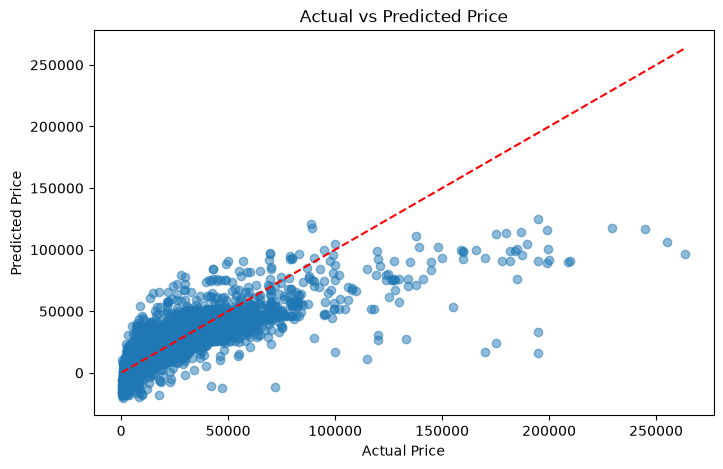

In [162]:
import seaborn as sns

plt.figure(figsize=(8,5))

plt.scatter(y_test, y_pred, alpha=0.5)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Price")

# Perfect prediction reference line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color='red',
    linestyle='--'
)


Text(0.5, 1.0, 'Residual Plot')

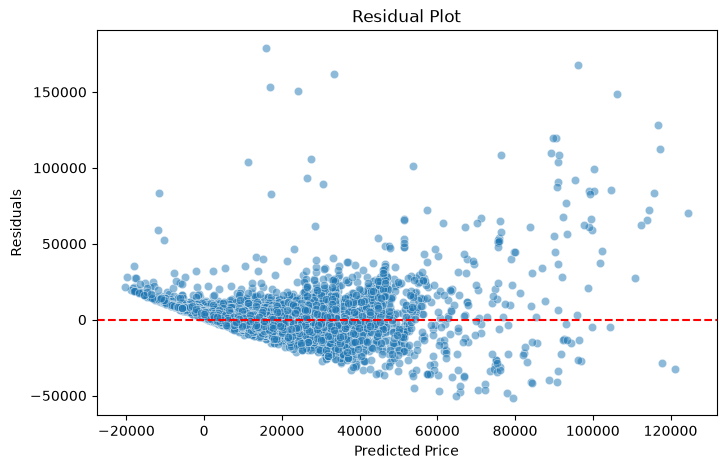

In [163]:
residuals = y_test - y_pred

plt.figure(figsize=(8,5))

sns.scatterplot(x=y_pred, y=residuals, alpha=0.5)

plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel("Predicted Price")
plt.ylabel("Residuals")
plt.title("Residual Plot")


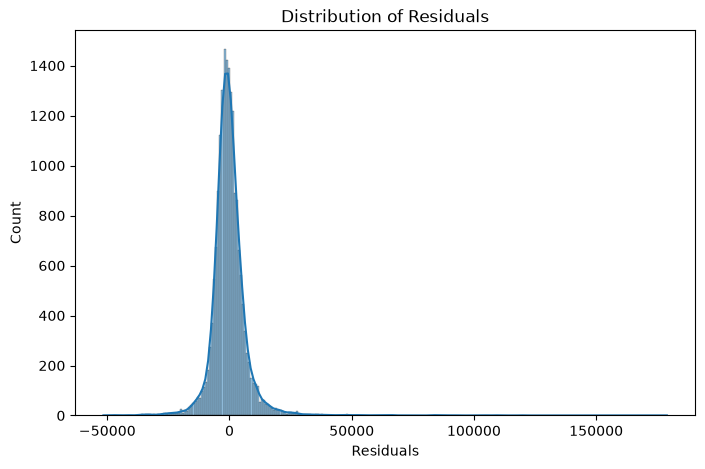

In [164]:
plt.figure(figsize=(8,5))

sns.histplot(residuals, kde=True)

plt.xlabel("Residuals")
plt.title("Distribution of Residuals")

plt.show()

In [166]:
print("R2 Score:", r2_score(y_test, y_pred))

print("MAE:", mean_absolute_error(y_test, y_pred))

print("MSE:", mean_squared_error(y_test, y_pred))

print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))

R2 Score: 0.6781175206271006
MAE: 4703.000470551008
MSE: 71448972.13333802
RMSE: 8452.74938309057
